# 12 · How long must Lazuli integrate to detect He I 10830 Å emission at S/N = 5 on a Sun-like star: with the IFS, or with a new 5 nm WCC filter?

The He I 10830 Å triplet is a chromospheric activity diagnostic (and, in transit, a tracer of escaping exoplanet atmospheres; arXiv:1711.05269). Here a G2V star of Johnson V magnitude 3 to 15 shows an **emission line at 10830 Å with intrinsic FWHM 0.1 Å**, present for the whole exposure. For each magnitude we ask **how long an exposure reaches S/N = 5 on the line**, with the star's own photon noise included, for:

- the **IFS** (`slicersim`), measuring the line in the R ≈ 100 spectrum;
- the **WCC** with a **new, hypothetical 5 nm top-hat filter** centred on 10830 Å, on the **qCMOS (HWK4123)** sensor (`wcc_etc` `qcmos:` noise model). The filter does not exist in `wcc_etc`; we build it.

The line is unresolved by both instruments, so what matters is its flux (or equivalent width, EW) against the noise of the star under it. The notebook ends by adapting WCC tutorial 05 (light curves): a time series at the S/N = 5 cadence with the line switched on in one exposure.

**Instrument / code:** Lazuli IFS, `slicersim` (`LazuliTarget`, `change_detector`); Lazuli WCC, `wcc_etc` (`Simulation.from_sensorfilter("qcmos:z")`, `set_sensor` on a top-hat throughput, both gain modes, `get_scene("emission", host=...)`).

**Off the hub:** `bash lazuli/install_lazuli_env.sh` (from the repository root) builds a virtual environment with both simulators.

## Prompt to try in Jupyter AI

> A G2V star (Johnson V from 3 to 15) shows a He I 10830 Å emission line, FWHM 0.1 Å, with peak equal to the continuum.
> (1) With `slicersim.LazuliTarget`, measure the line flux in the IFS spectrum over ±1 LSF FWHM, with the star's photon noise, and find the exposure time to S/N = 5 using MACC read-outs that do not saturate. Bin-integrate the line onto the IFS wavelength bins first.
> (2) With `wcc_etc`, build a 5 nm top-hat filter at 10830 Å on the `qcmos` sensor from the `qcmos:z` throughput, rebuild the sensor on it with `get_sensor_config` + `set_sensor`, check that it took effect, and find the exposure time to S/N = 5 with `get_scene("emission", lines=[...], host="G2V")` in both qCMOS gain modes, splitting the exposure into reads to avoid saturation.
> Plot both exposure times versus V, and a light curve at the S/N = 5 cadence. State what is assumed about the continuum.

## Setup

Two gotchas, both checked below:

- **slicersim samples a custom spectrum at the centre of each IFS wavelength bin** (gallery notebook 06). A 0.1 Å line would fall between samples and silently disappear, so we integrate the line over each IFS bin analytically before handing the spectrum over.
- **The new WCC filter** is written as a throughput file in the same format as the shipped `qcmos:z` curve, and the qCMOS sensor is rebuilt on it (`update_sensor` would not do: the bandpass is read when the sensor is created). Section 3 verifies that the ETC actually uses it before any number is computed.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if os.path.isdir(SRC) and not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory (off the hub, sncosmo's default is kept)
if os.path.isdir(DEST):
    os.environ['SNCOSMO_DATA_DIR'] = DEST

import tempfile
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import astropy.units as u
import matplotlib.pyplot as plt
from scipy.special import erf
import slicersim
import wcc_etc
from wcc_etc import Simulation, get_scene

print('slicersim', slicersim.__version__, '| wcc_etc', wcc_etc.__version__)
warnings.filterwarnings('ignore', message='spectrum')    # line-only spectra do not cover the whole filter: expected (WCC exercise 4)
trapezoid = getattr(np, 'trapezoid', None) or np.trapz

THUMB = Path('thumbs/12_he10830_ifs_vs_wcc.png')
LINE_WAVE = 10830.0        # Å, He I triplet (air)
LINE_FWHM = 0.1            # Å, intrinsic; unresolved by both instruments
LINE_PEAK = 1.0            # line peak / local continuum
EW_REF = LINE_PEAK * LINE_FWHM * np.sqrt(np.pi / (4 * np.log(2)))     # Å; Gaussian EW = 1.0645 x FWHM x peak
SNR_TARGET = 5.0
EVENT = 600.0              # s: duration of the line emission event (sections 4 and 5)
STAR = 'G2V'
MAG_BAND, MAG_SYS = 'johnson_v', 'vegamag'      # Johnson V (Vega)
FILTER_WIDTH = 50.0        # Å, top hat
BASE_LABEL = 'qcmos:z'     # HWK4123 qCMOS in z: telescope x QE at 1.08 µm and the sensor noise model
V_GRID = np.arange(3.0, 15.01, 0.25)
V0 = 18.0                  # reference magnitude: spectrum normalisation, faint end of the saturation search
print(f"line: FWHM {LINE_FWHM} Å, peak {LINE_PEAK} x continuum -> EW = {EW_REF * 1e3:.0f} mÅ; target S/N = {SNR_TARGET:g}")

slicersim 1.4.2 | wcc_etc 0.1.1
line: FWHM 0.1 Å, peak 1.0 x continuum -> EW = 106 mÅ; target S/N = 5


## 1. The star and the line

Both instruments see the same spectrum: the `wcc_etc` G2V (Pickles) template normalised to Johnson V (Vega), evaluated from 3000 to 20 000 Å and handed to slicersim as an absolute flux. The line flux scales with the star: $F_\mathrm{line} = \mathrm{EW}\times F_\lambda^\mathrm{cont}(10830)$, with the continuum averaged over the 50 Å filter window.

In [2]:
LAM = np.arange(3000.0, 20000.0, 1.0)

def star_scene(v, **kw):
    return get_scene(STAR, mag=float(v), bandpass=MAG_BAND, magsys=MAG_SYS, **kw)

def template_flam(scene):
    _, flam = scene.source.get_spectrum(as_array=True, wave=LAM * u.AA, flux_unit='flam')
    return np.asarray(getattr(flam, 'value', flam), dtype=float)

FLAM_V0 = template_flam(star_scene(V0))          # erg/s/cm2/Å at V = V0
assert np.all(np.isfinite(FLAM_V0)) and np.all(FLAM_V0 > 0), 'the G2V template does not cover 3000-20000 Å'
IN_BAND = np.abs(LAM - LINE_WAVE) <= FILTER_WIDTH / 2
FCONT_V0 = FLAM_V0[IN_BAND].mean()

def scale(v):
    return 10 ** (-0.4 * (np.asarray(v) - V0))

def fcont(v):
    return FCONT_V0 * scale(v)                # erg/s/cm2/Å under the line

def line_flux(v, ew=EW_REF):
    return ew * fcont(v)                      # erg/s/cm2

f_z = template_flam(get_scene(STAR, mag=V0, bandpass='sdss_z', magsys='abmag'))[IN_BAND].mean()
print(f"G2V at V = {V0:g}: continuum at {LINE_WAVE:.0f} Å = {FCONT_V0:.3e} erg/s/cm2/Å; line flux = {line_flux(V0):.3e} erg/s/cm2; "
      f"template colour V - z'(AB) = {2.5 * np.log10(FCONT_V0 / f_z):.2f}")

G2V at V = 18: continuum at 10830 Å = 8.132e-17 erg/s/cm2/Å; line flux = 8.656e-18 erg/s/cm2; template colour V - z'(AB) = 1.04


## 2. The IFS (slicersim)

The star is a point source in the narrow field. The H4RG is read up the ramp every $t_\mathrm{frame}$ = 2.83 s. An exposure is a number of identical ramps of one MACC read-out: short ramps for bright stars (fewer frames before a pixel saturates), long ramps for faint ones (the read noise is paid per ramp). Each read-out's exposure is rounded up to whole ramps.

**Measurement** (as in gallery notebook 06): line signal = (spectrum with line) − (spectrum without) summed over ±1 LSF FWHM, times the bin width; noise = $\sqrt{\sum \sigma^2\,d\lambda^2}$ from the variance of the spectrum *with* the line, so the star's (and the line's) photon noise is in. Subtracting the noise-free continuum means **the continuum is assumed known**, e.g. from line-free exposures of the same star (with a single reference exposure of equal length the error grows by √2).

Every magnitude and ramp is simulated directly (two noise-free runs: star, and star + line). A linear-in-flux shortcut is not accurate here: the noise of slicersim's extracted spectrum is not exactly linear in the star's flux (a linear model calibrated at V = 18 is 7 % off at V = 12). $N$ identical ramps give $\sqrt{N}$ times the S/N of one, which a full run checks.

In [3]:
probe = slicersim.LazuliTarget(LAM, FLAM_V0)
LB = probe.simulation.spectrograph.lbda
EDGES = np.r_[LB[0] - (LB[1] - LB[0]) / 2, (LB[1:] + LB[:-1]) / 2, LB[-1] + (LB[-1] - LB[-2]) / 2]
IDX = np.searchsorted(EDGES, LAM)              # label i <-> IFS bin between EDGES[i-1] and EDGES[i]
NB = len(EDGES) + 1
SIG_LINE = LINE_FWHM / (2 * np.sqrt(2 * np.log(2)))

def bin_average(flux):
    mean = np.bincount(IDX, flux, minlength=NB) / np.maximum(np.bincount(IDX, minlength=NB), 1)
    return mean[IDX]

def line_per_bin(F):
    # Gaussian line of total flux F integrated exactly over each IFS bin -> bin-mean flux density (erg/s/cm2/Å)
    cdf = 0.5 * (1 + erf((EDGES - LINE_WAVE) / (np.sqrt(2) * SIG_LINE)))
    return np.r_[0.0, F * np.diff(cdf) / np.diff(EDGES), 0.0]

def line_binned(F):
    return line_per_bin(F)[IDX]                 # on the LAM grid, constant within each IFS bin

STAR_BINNED = bin_average(FLAM_V0)
assert np.isclose(np.sum(line_per_bin(1.0)[1:-1] * np.diff(EDGES)), 1.0), 'line flux not conserved'

lr, R = probe.simulation.get_resolving_power()
R_LINE = np.interp(LINE_WAVE, lr, R)
FWHM_LSF = LINE_WAVE / R_LINE
DL = np.gradient(LB)
WIN = np.abs(LB - LINE_WAVE) <= FWHM_LSF
TFRAME = probe.get_properties('tframe')
print(f"IFS at {LINE_WAVE:.0f} Å: R = {R_LINE:.0f}, LSF FWHM = {FWHM_LSF:.0f} Å, pixel = {np.interp(LINE_WAVE, LB, DL):.0f} Å, "
      f"window ±1 FWHM = {WIN.sum()} bins; t_frame = {TFRAME} s")
print(f"the 0.1 Å line is diluted ~{FWHM_LSF / LINE_FWHM:.0f}x by the LSF")

RAMPS = [(2, 1, 0), (3, 1, 0), (7, 1, 0), (21, 1, 0), (64, 1, 0), (64, 4, 0), (64, 8, 0)]   # short ramps first
for n, m, d in RAMPS:
    print(f"ramp nmd = {(n, m, d)!s:11s}: {(n * (m + d) - d) * TFRAME:7.1f} s")

IFS at 10830 Å: R = 102, LSF FWHM = 107 Å, pixel = 46 Å, window ±1 FWHM = 5 bins; t_frame = 2.83 s
the 0.1 Å line is diluted ~1065x by the LSF
ramp nmd = (2, 1, 0)  :     5.7 s
ramp nmd = (3, 1, 0)  :     8.5 s
ramp nmd = (7, 1, 0)  :    19.8 s
ramp nmd = (21, 1, 0) :    59.4 s
ramp nmd = (64, 1, 0) :   181.1 s
ramp nmd = (64, 4, 0) :   724.5 s
ramp nmd = (64, 8, 0) :  1449.0 s


In [4]:
def ifs_run(flux, nmd, nramps=1):
    # noise-free spectrum, its variance (flambda), saturation flag and exposure time
    t = slicersim.LazuliTarget(LAM, flux)
    t.change_detector(nmd=nmd, nramps=nramps)
    _, f, v = t.get_spectrum(unit='flambda', incl_error=False)
    return f, v, bool(t.simulation.detector.nsaturated_detpx), t.get_exposure_time()

def wsum(v):
    return np.sum(v[WIN] * DL[WIN] ** 2)

def ifs_snr(v, nmd, nramps=1):
    # line S/N, saturation flag and exposure time for the star at V = v with the line on
    F = line_flux(v)
    f_c, _, sat, t = ifs_run(STAR_BINNED * scale(v), nmd, nramps)
    f_l, v_l, _, _ = ifs_run(STAR_BINNED * scale(v) + line_binned(F), nmd, nramps)
    return np.sum((f_l - f_c)[WIN] * DL[WIN]) / np.sqrt(wsum(v_l)), sat, t

TRAMP = {}
for nmd in RAMPS:
    f_c, _, _, TRAMP[nmd] = ifs_run(STAR_BINNED, nmd)
    f_l, _, _, _ = ifs_run(STAR_BINNED + line_binned(line_flux(V0)), nmd)
    eff = np.sum((f_l - f_c)[WIN] * DL[WIN]) / line_flux(V0)
    s12, sat12, _ = ifs_snr(12.0, nmd)
    print(f"{nmd!s:11s}: ramp {TRAMP[nmd]:7.1f} s, line recovered in the window {eff:.0%}, S/N per ramp at V = 12: "
          + ("saturated" if sat12 else f"{s12:.3f}"))

# N identical ramps give sqrt(N) times the S/N of one
s1, _, _ = ifs_snr(13.0, (21, 1, 0), 1)
s9, _, _ = ifs_snr(13.0, (21, 1, 0), 9)
print(f"V = 13, (21, 1, 0): S/N {s1:.3f} in 1 ramp, {s9:.3f} in 9 ramps (3 x {s1:.3f} = {3 * s1:.3f})")
assert np.isclose(s9, 3 * s1, rtol=0.02)

(2, 1, 0)  : ramp     5.7 s, line recovered in the window 98%, S/N per ramp at V = 12: 0.190


(3, 1, 0)  : ramp     8.5 s, line recovered in the window 98%, S/N per ramp at V = 12: 0.280


(7, 1, 0)  : ramp    19.8 s, line recovered in the window 98%, S/N per ramp at V = 12: 0.489


(21, 1, 0) : ramp    59.4 s, line recovered in the window 98%, S/N per ramp at V = 12: saturated


(64, 1, 0) : ramp   181.1 s, line recovered in the window 98%, S/N per ramp at V = 12: saturated


(64, 4, 0) : ramp   724.5 s, line recovered in the window 98%, S/N per ramp at V = 12: saturated


(64, 8, 0) : ramp  1449.0 s, line recovered in the window 98%, S/N per ramp at V = 12: saturated


V = 13, (21, 1, 0): S/N 0.550 in 1 ramp, 1.651 in 9 ramps (3 x 0.550 = 1.651)


**Bright limit and exposure time.** For each ramp, bisect in V for the magnitude where the first detector pixel saturates (gallery notebook 07's criterion, `detector.nsaturated_detpx`). Then, at each magnitude and for each unsaturated ramp, $N = \lceil (5/\mathrm{S/N}_\mathrm{ramp})^2 \rceil$ ramps reach S/N = 5; we keep the ramp with the shortest total time.

In [5]:
def ifs_saturates(v, nmd):
    return ifs_run(STAR_BINNED * scale(v), nmd)[2]

def ifs_bright_limit(nmd, lo=2.0, hi=V0, tol=0.05):
    if not ifs_saturates(lo, nmd):
        return lo
    while hi - lo > tol:                         # lo saturates, hi does not
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if ifs_saturates(mid, nmd) else (lo, mid)
    return hi

IFS_SAT = {nmd: ifs_bright_limit(nmd) for nmd in RAMPS}
for nmd, vs in IFS_SAT.items():
    print(f"{nmd!s:11s}: unsaturated for V > {vs:.2f}")

ifs_t5 = np.full(V_GRID.size, np.nan)
ifs_choice = [None] * V_GRID.size
ifs_snr10 = np.full(V_GRID.size, np.nan)         # S/N for the 10-minute event: as many whole ramps as fit in it
ifs_choice10 = [None] * V_GRID.size
for i, v in enumerate(V_GRID):
    best = None
    for nmd in RAMPS:
        if v <= IFS_SAT[nmd]:
            continue
        s1 = ifs_snr(v, nmd)[0]
        N = int(np.ceil((SNR_TARGET / s1) ** 2))
        t = N * TRAMP[nmd]
        if best is None or t < best[0]:
            best = (t, nmd, N, s1 * np.sqrt(N))
        n10 = int(EVENT // TRAMP[nmd])
        if n10 >= 1 and not s1 * np.sqrt(n10) <= ifs_snr10[i]:
            ifs_snr10[i], ifs_choice10[i] = s1 * np.sqrt(n10), (nmd, n10)
    if best:
        ifs_t5[i], ifs_choice[i] = best[0], best[1:]
print(f"IFS brightest usable V = {V_GRID[np.isfinite(ifs_t5)][0]:.2f}")

(2, 1, 0)  : unsaturated for V > 8.88
(3, 1, 0)  : unsaturated for V > 9.62
(7, 1, 0)  : unsaturated for V > 10.81
(21, 1, 0) : unsaturated for V > 12.12
(64, 1, 0) : unsaturated for V > 13.38
(64, 4, 0) : unsaturated for V > 14.88
(64, 8, 0) : unsaturated for V > 15.62


IFS brightest usable V = 9.00


## 3. The WCC: a new 5 nm top-hat filter on the qCMOS (HWK4123)

`qcmos:z` has total throughput = telescope × z′ filter × HWK4123 QE (a CSV in nm shipped with `wcc_etc`). The new filter is a **top hat from 10805 to 10855 Å whose transmission equals the z′ filter's at 1.08 µm**, i.e. the new total throughput is the `qcmos:z` curve inside the top hat and zero outside. The sensor noise model is unchanged. The HWK4123 has two gain modes and we keep the better one at each magnitude:

- **high** (32×): measured read noise 0.25 e⁻ (doubled in the config as a margin), but the 12-bit ADC clips at ≈ 552 e⁻;
- **low** (1×): read noise 2.33 e⁻ (doubled), 7500 e⁻ well.

First, what the shipped `qcmos:z` curve says at 10830 Å: silicon QE is falling steeply here.

qcmos:z: pivot 9040 Å, total throughput at 10830 Å = 0.0028 (curve peak 0.194); PSF AiryPSF; min frame 0.008 s
  gain high: read noise 0.50 electron / pix, saturation 552 electron (adc limited), dark 0.05 electron / (pix s)
  gain low : read noise 4.66 electron / pix, saturation 7500 electron (well limited), dark 0.05 electron / (pix s)


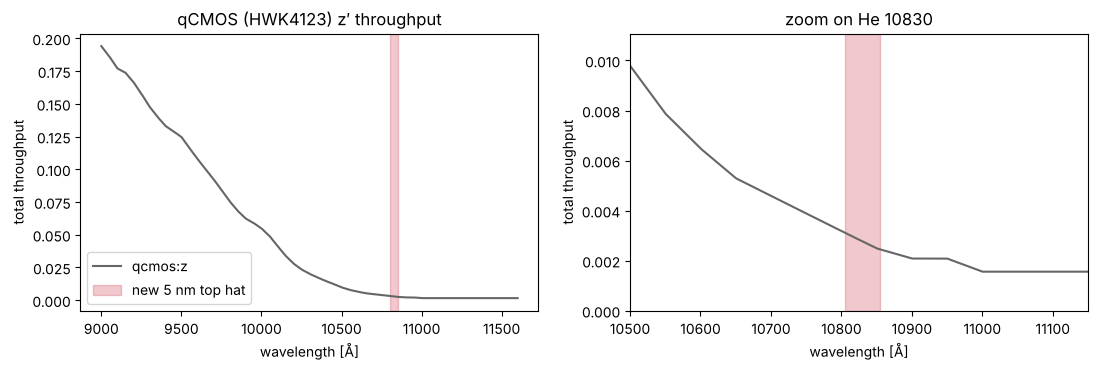

In [6]:
GAIN_MODES = ('high', 'low')
base = Simulation.from_sensorfilter(BASE_LABEL, star_scene(V0))
W = np.arange(9000.0, 11600.0, 0.1)
T_base = base.sensor.bandpass(W).value
T_LINE = float(base.sensor.bandpass(LINE_WAVE).value)
MIN_FRAME = float(base.sensor.meta.get('min_frame_time', 0.008))
print(f"{BASE_LABEL}: pivot {float(base.sensor.bandpass.pivot().value):.0f} Å, total throughput at {LINE_WAVE:.0f} Å = {T_LINE:.4f} "
      f"(curve peak {T_base.max():.3f}); PSF {type(base.default_psf).__name__}; min frame {MIN_FRAME} s")
for gm in GAIN_MODES:
    sen = Simulation.from_sensorfilter(BASE_LABEL, star_scene(V0), gain_mode=gm).sensor
    print(f"  gain {gm:4s}: read noise {sen.read_noise:.2f}, saturation {sen.saturation_e:.0f} ({sen.saturation_limit} limited), dark {sen.dark_current}")
if not T_LINE > 1e-5:
    raise RuntimeError(f"{BASE_LABEL} throughput is ~0 at {LINE_WAVE} Å: the shipped curve does not reach He 10830.")

fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 3.6))
for a in (ax, bx):
    a.plot(W, T_base, color='0.4', label=BASE_LABEL)
    a.axvspan(LINE_WAVE - FILTER_WIDTH / 2, LINE_WAVE + FILTER_WIDTH / 2, color='#d1495b', alpha=0.3, label='new 5 nm top hat')
    a.set(xlabel='wavelength [Å]', ylabel='total throughput')
bx.set(xlim=(10500, 11150), ylim=(0, 4 * T_LINE), title='zoom on He 10830')
ax.set(title='qCMOS (HWK4123) z′ throughput')
ax.legend()
plt.show()

**Build and install the filter.** `update_sensor()` only edits the sensor's parameter dictionary: the bandpass is read when the sensor is created. So we write the top hat in the format of the shipped curve and rebuild the qCMOS sensor on it with `set_sensor()`, keeping everything else from `from_sensorfilter` (scene, in-focus Airy PSF, gain mode).

In [7]:
from wcc_etc import get_sensor_config
from wcc_etc.io import expand_path

orig_path = Path(expand_path(base.sensor.meta['path_total_throughput']))
orig = pd.read_csv(orig_path)
wcol, tcol = orig.columns[:2]
w_file_nm, t_file = orig[wcol].to_numpy(float), orig[tcol].to_numpy(float)
probe_w = W[T_base > 0.2 * T_base.max()]
assert np.allclose(np.interp(probe_w / 10, w_file_nm, t_file), base.sensor.bandpass(probe_w).value, rtol=1e-3, atol=1e-6), \
    f'{orig_path.name} does not match the installed bandpass in nm'
print(f"{orig_path.name}: columns ({wcol}, {tcol}), wavelength in nm, {len(orig)} rows")

lo, hi = (LINE_WAVE - FILTER_WIDTH / 2) / 10, (LINE_WAVE + FILTER_WIDTH / 2) / 10        # nm
w_new = np.unique(np.r_[w_file_nm[(w_file_nm < lo - 0.1) | (w_file_nm > hi + 0.1)], lo - 1e-4, np.linspace(lo, hi, 101), hi + 1e-4])
t_new = np.where((w_new >= lo) & (w_new <= hi), np.interp(w_new, w_file_nm, t_file), 0.0)
TOPHAT_PATH = Path(tempfile.mkdtemp()) / 'wcc_qcmos_he10830_tophat_throughput.csv'
pd.DataFrame({wcol: w_new, tcol: t_new}).to_csv(TOPHAT_PATH, index=False)

def tophat_sim(scene, gain_mode='high'):
    # qcmos:z simulation (in-focus Airy PSF, HWK4123 noise model), sensor rebuilt on the top-hat throughput
    sim = Simulation.from_sensorfilter(BASE_LABEL, scene, gain_mode=gain_mode)
    cfg = get_sensor_config('qcmos', 'z', gain_mode=gain_mode)['sensor']
    cfg['path_total_throughput'] = str(TOPHAT_PATH)
    sim.set_sensor(cfg)
    return sim

nb = tophat_sim(star_scene(V0))
T_nb = nb.sensor.bandpass(W).value
T_want = np.where(np.abs(W - LINE_WAVE) <= FILTER_WIDTH / 2, T_base, 0.0)
edge = np.abs(np.abs(W - LINE_WAVE) - FILTER_WIDTH / 2) < 0.6
assert np.allclose(T_nb[~edge], T_want[~edge], atol=1e-3 * T_LINE), 'the installed bandpass is not the top hat'
RECT = trapezoid(T_nb, W) / float(nb.sensor.bandpass(LINE_WAVE).value)
print(f"new filter installed: pivot {float(nb.sensor.bandpass.pivot().value):.1f} Å, rectangular width {RECT:.1f} Å, "
      f"T({LINE_WAVE:.0f}) = {float(nb.sensor.bandpass(LINE_WAVE).value):.4f}")

wcc_hwk_z_throughput.csv: columns (Wavelength, hwk_z), wavelength in nm, 161 rows
new filter installed: pivot 10829.0 Å, rectangular width 50.1 Å, T(10830) = 0.0028


**Does the ETC use it, and does it see a 0.1 Å line?** A line outside the top hat (10700 Å, still inside z′) must vanish, and a 0.1 Å line must give the same S/N as a 2 Å one (the filter is flat across both).

In [8]:
def line_scene(F, wave=LINE_WAVE, fwhm=LINE_FWHM, v=None):
    kw = {} if v is None else dict(host=STAR, host_prop={'mag': float(v), 'bandpass': MAG_BAND, 'magsys': MAG_SYS})
    return get_scene('emission', mag=None, lines=[{'wave': wave, 'flux': float(F), 'fwhm': fwhm}], **kw)

def snr_line(scene, t=60.0):
    try:
        return tophat_sim(scene).get_image_snr(t, warn=False)['snr']
    except ValueError as err:                  # wcc_etc refuses a source with no flux through the bandpass
        if 'no positive photon flux' in str(err):
            return 0.0
        raise

s_in, s_out, s_wide = snr_line(line_scene(1e-15)), snr_line(line_scene(1e-15, wave=10700.0)), snr_line(line_scene(1e-15, fwhm=2.0))
print(f"pure 1e-15 erg/s/cm2 line, 60 s: S/N {s_in:.1f} at 10830 Å (FWHM 0.1 Å), {s_wide:.1f} (FWHM 2 Å), {s_out:.2f} at 10700 Å")
assert s_out < 0.01 * s_in, 'a line outside the top hat is still detected: the filter is not applied'
assert np.isclose(s_in, s_wide, rtol=0.02), 'the 0.1 Å line is not sampled correctly by wcc_etc'

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


pure 1e-15 erg/s/cm2 line, 60 s: S/N 0.5 at 10830 Å (FWHM 0.1 Å), 0.5 (FWHM 2 Å), 0.00 at 10700 Å


**Exposure time versus magnitude.** The line is the source and the G2V star is a point-source host under it (WCC exercise 4), so `get_image_snr` returns the line S/N with the star's photon noise. The frame time comes from the peak pixel (gallery notebook 10): the longest frame, up to 60 s, that keeps the brightest pixel below 80 % of saturation. With a fixed frame time every noise term (star, line, sky, dark, and read noise per frame) grows linearly with the exposure, so S/N ∝ √t and one 60 s evaluation gives $t_5 = 60\,\mathrm{s}\times(5/\mathrm{S/N}_{60})^2$; full runs at $t_5$ check this. Both gain modes are run and the shorter time kept. The star alone in the same filter must reproduce σ(EW) = σ_rel × rectangular width.

In [9]:
T_UNIT, FRAME_MAX = 60.0, 60.0

def frame_time(sim):
    # longest frame (<= FRAME_MAX) keeping the brightest pixel below 80 % of saturation; None if below the minimum frame
    peak = sim.get_peak_pixel(1.0, units='e-').value              # e- in the brightest pixel in 1 s
    tf = min(FRAME_MAX, 0.8 * sim.sensor.saturation_e.value / peak)
    return None if tf < MIN_FRAME else tf

def n_reads(t, tf):
    return max(1, int(np.ceil(t / tf)))

SIMS = {gm: (tophat_sim(line_scene(line_flux(V0), v=V0), gm), tophat_sim(star_scene(V0), gm)) for gm in GAIN_MODES}

def wcc_point(v, gm):
    # (t5 [s], frame time [s], S/N in 60 s, star-only ppm in 60 s) for gain mode gm, or None if saturated
    wl, ws = SIMS[gm]
    wl.update(host__mag=float(v))
    wl.update(source__lines=[{'wave': LINE_WAVE, 'flux': float(line_flux(v)), 'fwhm': LINE_FWHM}])
    tf = frame_time(wl)
    if tf is None:
        return None
    r = wl.get_image_snr(T_UNIT, n_reads=n_reads(T_UNIT, tf), warn=False)
    if r['saturated']:
        return None
    ws.update(source__mag=float(v))
    ppm = 1e6 / ws.get_image_snr(T_UNIT, n_reads=n_reads(T_UNIT, tf), warn=False)['snr']
    return T_UNIT * (SNR_TARGET / r['snr']) ** 2, tf, r['snr'], ppm

wcc_t5 = np.full(V_GRID.size, np.nan)
wcc_snr60 = np.full(V_GRID.size, np.nan)
wcc_ppm = np.full(V_GRID.size, np.nan)
wcc_tf = np.full(V_GRID.size, np.nan)
wcc_gain = [None] * V_GRID.size
for i, v in enumerate(V_GRID):
    pts = {gm: p for gm in GAIN_MODES if (p := wcc_point(v, gm)) is not None}
    if pts:
        gm = min(pts, key=lambda g: pts[g][0])
        wcc_t5[i], wcc_tf[i], wcc_snr60[i], wcc_ppm[i] = pts[gm]
        wcc_gain[i] = gm
assert float(SIMS['high'][0].sensor.bandpass(LINE_WAVE + 40).value) < 1e-6, 'update() reverted the filter'
wcc_snr10 = wcc_snr60 * np.sqrt(EVENT / T_UNIT)     # S/N for the 10-minute event (fixed frame time: S/N grows as sqrt(t))

# checks: S/N at t5 from a full run, and sigma_EW = star-only precision x rectangular width
for v in (6.0, 12.0):
    i = np.argmin(np.abs(V_GRID - v))
    wl = SIMS[wcc_gain[i]][0]
    wl.update(host__mag=float(v))
    wl.update(source__lines=[{'wave': LINE_WAVE, 'flux': float(line_flux(v)), 'fwhm': LINE_FWHM}])
    s5 = wl.get_image_snr(wcc_t5[i], n_reads=n_reads(wcc_t5[i], wcc_tf[i]), warn=False)['snr']
    print(f"V = {v:g}: t5 = {wcc_t5[i]:.0f} s ({wcc_gain[i]} gain, {wcc_tf[i]:.3g} s frames) -> full run S/N = {s5:.2f}")
    assert np.isclose(s5, SNR_TARGET, rtol=0.03)
ok = np.isfinite(wcc_t5)
ratio = (EW_REF / wcc_snr60) / (wcc_ppm * 1e-6 * RECT)
print(f"sigma_EW (line run) / (star-only precision x {RECT:.1f} Å): median {np.nanmedian(ratio):.3f}, range {np.nanmin(ratio):.3f}-{np.nanmax(ratio):.3f}")
assert 0.9 < np.nanmedian(ratio) < 1.1
for gm in GAIN_MODES:
    vs = [v for v, g in zip(V_GRID, wcc_gain) if g == gm]
    if vs:
        print(f"{gm} gain is better for V = {min(vs):g}-{max(vs):g}")
print(f"WCC brightest usable V = {V_GRID[ok][0]:.2f} ({wcc_tf[ok][0]:.3g} s frames)")

V = 6: t5 = 241 s (high gain, 0.273 s frames) -> full run S/N = 5.00
V = 12: t5 = 61711 s (high gain, 60 s frames) -> full run S/N = 5.00
sigma_EW (line run) / (star-only precision x 50.1 Å): median 0.999, range 0.999-0.999
high gain is better for V = 3-15
WCC brightest usable V = 3.00 (0.0172 s frames)


## 4. Comparison

Exposure time to reach S/N = 5 on the line (EW ≈ 106 mÅ, peak = continuum), and the S/N reached if the emission lasts **10 minutes** (the IFS in as many whole ramps as fit in it). In the photon-limited regime the time scales as $1/\mathrm{EW}^2$: a line twice as strong needs a quarter of the time.

In [10]:
def fmt_t(t):
    if not np.isfinite(t):
        return 'saturated'
    for lim, div, unit in ((120, 1, 's'), (7200, 60, 'min'), (2 * 86400, 3600, 'h')):
        if t < lim:
            return f"{t / div:.1f} {unit}"
    return f"{t / 86400:.1f} d"

print(f"time to S/N = {SNR_TARGET:g} on a FWHM {LINE_FWHM} Å, EW {EW_REF * 1e3:.0f} mÅ He I 10830 line, G2V star")
print(f"{'':>5} | {'IFS':^41} | {'WCC 5 nm filter':^41} |")
print(f"{'V':>5} | {'t(S/N=5)':>10} {'ramps':>18} {'S/N 10 min':>11} | {'t(S/N=5)':>10} {'gain':>4} {'frame':>9} {'S/N 10 min':>11} | {'WCC/IFS':>7}")
for vv in (3, 4, 6, 8, 10, 12, 14, 15):
    i = np.argmin(np.abs(V_GRID - vv))
    c = ifs_choice[i]
    ramps = f"{c[1]} x {c[0]}" if c else ''
    gm = wcc_gain[i] or ''
    fr = f"{wcc_tf[i]:.3g} s" if np.isfinite(wcc_tf[i]) else ''
    print(f"{vv:5.1f} | {fmt_t(ifs_t5[i]):>10} {ramps:>18} {ifs_snr10[i]:11.1f} | {fmt_t(wcc_t5[i]):>10} {gm:>4} {fr:>9} {wcc_snr10[i]:11.1f} | {wcc_t5[i] / ifs_t5[i]:7.1f}")
for name, snr10 in (('IFS', ifs_snr10), ('WCC 5 nm', wcc_snr10)):
    ok5 = V_GRID[np.isfinite(snr10) & (snr10 >= SNR_TARGET)]
    print(f"{name}: S/N >= {SNR_TARGET:g} for a 10-minute event at V = {ok5.min():g}-{ok5.max():g}" if ok5.size else f"{name}: never S/N {SNR_TARGET:g} in 10 min")

time to S/N = 5 on a FWHM 0.1 Å, EW 106 mÅ He I 10830 line, G2V star
      |                    IFS                    |              WCC 5 nm filter              |
    V |   t(S/N=5)              ramps  S/N 10 min |   t(S/N=5) gain     frame  S/N 10 min | WCC/IFS
  3.0 |  saturated                            nan |     15.2 s high  0.0172 s        31.4 |     nan
  4.0 |  saturated                            nan |     38.2 s high  0.0433 s        19.8 |     nan
  6.0 |  saturated                            nan |    4.0 min high   0.273 s         7.9 |     nan
  8.0 |  saturated                            nan |   25.3 min high    1.72 s         3.1 |     nan
 10.0 |    6.7 min     47 x (3, 1, 0)         6.2 |      2.7 h high    10.9 s         1.2 |    24.1
 12.0 |   34.7 min    105 x (7, 1, 0)         2.7 |     17.1 h high      60 s         0.5 |    29.7
 14.0 |      3.4 h    68 x (64, 1, 0)         1.1 |      5.0 d high      60 s         0.2 |    35.2
 15.0 |      8.6 h   170 x (64, 1, 

## 5. A light curve with a 10-minute emission event (adapted from WCC tutorial 05)

Tutorial 05 draws white noise from the ETC S/N around a transit model. Here the model is the line EW: zero, except during a **line emission event lasting 10 minutes**. Both instruments expose back to back for 10 minutes (the IFS in whole ramps, just under 10 minutes), and the event fills one exposure. Time is measured from the middle of the event. For the narrowband filter the same series in relative flux is $1 + \mathrm{EW}/W_\mathrm{rect}$. As in tutorial 05, only white noise is modelled.

In [11]:
V_DEMO = 10.0
i = np.argmin(np.abs(V_GRID - V_DEMO))
k_exp = np.arange(-15, 16)                       # 10-minute exposures, the event fills exposure 0
ew_true = np.where(k_exp == 0, EW_REF, 0.0)
rng = np.random.default_rng(3)
LC = {}
c10 = ifs_choice10[i]
for name, s, how in (('IFS', ifs_snr10[i], f"{c10[1]} x {c10[0]} ramps = {c10[1] * TRAMP[c10[0]] / 60:.1f} min" if c10 else ''),
                     ('WCC 5 nm (qCMOS)', wcc_snr10[i], f"{wcc_gain[i]} gain, {wcc_tf[i]:.3g} s frames")):
    if np.isfinite(s):
        sig = EW_REF / s
        LC[name] = (k_exp * EVENT / 60, ew_true + rng.normal(0, sig, k_exp.size), sig)
        print(f"{name:18s} V = {V_DEMO:g}: 10-minute event ({how}): sigma_EW {sig * 1e3:5.1f} mÅ, line at {s:.1f} sigma")
if 'WCC 5 nm (qCMOS)' in LC:
    print(f"narrowband relative flux with the line on: 1 + {EW_REF / RECT * 1e6:.0f} ppm")

IFS                V = 10: 10-minute event (70 x (3, 1, 0) ramps = 9.9 min): sigma_EW  17.3 mÅ, line at 6.2 sigma
WCC 5 nm (qCMOS)   V = 10: 10-minute event (high gain, 10.9 s frames): sigma_EW  85.2 mÅ, line at 1.2 sigma
narrowband relative flux with the line on: 1 + 2124 ppm


## Hero figure

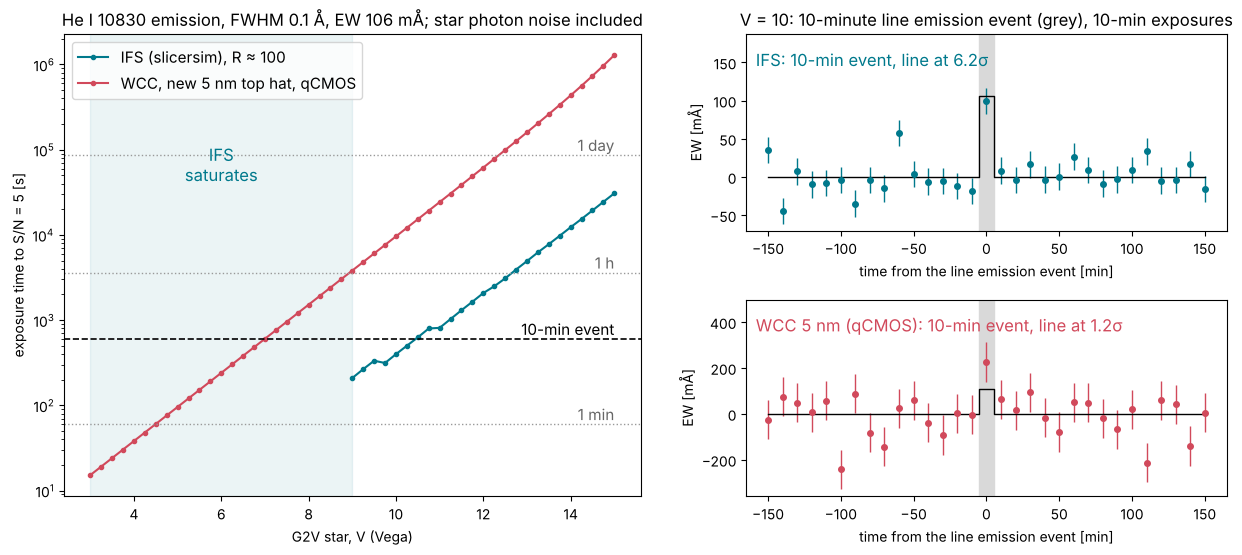

In [12]:
cols = {'IFS': '#00798c', 'WCC 5 nm (qCMOS)': '#d1495b'}
fig = plt.figure(figsize=(15, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1], hspace=0.35)
ax = fig.add_subplot(gs[:, 0])
ax.semilogy(V_GRID, ifs_t5, 'o-', ms=3, color=cols['IFS'], label='IFS (slicersim), R ≈ 100')
ax.semilogy(V_GRID, wcc_t5, 'o-', ms=3, color=cols['WCC 5 nm (qCMOS)'], label='WCC, new 5 nm top hat, qCMOS')
for t, lab in ((60, '1 min'), (3600, '1 h'), (86400, '1 day')):
    ax.axhline(t, color='0.6', ls=':', lw=1)
    ax.text(V_GRID[-1], t * 1.12, lab, color='0.4', fontsize=11, ha='right')
ax.axhline(EVENT, color='k', ls='--', lw=1.2)
ax.text(V_GRID[-1], EVENT * 1.12, '10-min event', color='k', fontsize=11, ha='right')
for name, arr in (('IFS', ifs_t5), ('WCC 5 nm (qCMOS)', wcc_t5)):
    ok = np.isfinite(arr)
    if ok.any() and not ok[0]:
        ax.axvspan(V_GRID[0], V_GRID[ok][0], color=cols[name], alpha=0.08)
        ax.text(0.5 * (V_GRID[0] + V_GRID[ok][0]), np.nanmax(wcc_t5) / 30, f'{name.split()[0]}\nsaturates', ha='center', color=cols[name], fontsize=12)
ax.set(xlabel='G2V star, V (Vega)', ylabel='exposure time to S/N = 5 [s]',
       title=f'He I 10830 emission, FWHM 0.1 Å, EW {EW_REF * 1e3:.0f} mÅ; star photon noise included')
ax.legend(loc='upper left', fontsize=11)

for k, (name, (t_min, ew, sig)) in enumerate(LC.items()):
    bx = fig.add_subplot(gs[k, 1])
    bx.axvspan(-0.5 * EVENT / 60, 0.5 * EVENT / 60, color='0.85', zorder=0)
    bx.errorbar(t_min, ew * 1e3, yerr=sig * 1e3, fmt='o', ms=4, color=cols[name], capsize=0, lw=1)
    bx.step(t_min, ew_true * 1e3, where='mid', color='k', lw=1)
    bx.text(0.02, 0.92, f"{name}: 10-min event, line at {EW_REF / sig:.1f}σ", transform=bx.transAxes, va='top', fontsize=12, color=cols[name])
    top = max((ew + sig).max(), EW_REF) * 1e3
    bx.set_ylim(top=1.6 * top)                    # headroom for the label
    bx.set(ylabel='EW [mÅ]', xlabel='time from the line emission event [min]')
    if k == 0:
        bx.set_title(f"V = {V_DEMO:g}: 10-minute line emission event (grey), 10-min exposures")
fig.savefig(THUMB, dpi=150, bbox_inches='tight')
plt.show()

## Answer

For a 0.1 Å-FWHM He I 10830 line whose peak equals the continuum (EW ≈ 106 mÅ) on a G2V star (numbers from slicersim 1.4.2 and wcc_etc 0.1.1):

- **IFS:** usable from V ≈ 9; brighter stars saturate even the shortest (5.7 s) ramp. S/N = 5 takes about 3.5 min at V = 9, 6.7 min at V = 10, 35 min at V = 12, 3.4 h at V = 14 and 8.6 h at V = 15.
- **WCC, new 5 nm filter on the qCMOS (HWK4123):** 24–42× longer than the IFS at the same V for V = 10–15 (2.7 h at V = 10, 17 h at V = 12, 5 d at V = 14), because the qCMOS z′ total throughput at 1.083 µm is only 0.28 % (silicon QE). Its niche is the bright stars the IFS cannot take: S/N = 5 in 15 s at V = 3, 38 s at V = 4, 4 min at V = 6 and 25 min at V = 8, in high gain with 0.02–2 s frames. High gain beats low gain at every magnitude.

**For an emission event lasting 10 minutes**, S/N ≥ 5 needs V = 9–10.25 with the IFS (S/N 6.2 at V = 10, 2.7 at V = 12) or V ≤ 6.75 with the WCC filter (S/N 31 at V = 3, 7.9 at V = 6, 1.2 at V = 10). The two instruments cover complementary ranges with a gap around V ≈ 7–9, where neither reaches 5σ in 10 minutes. The time scales as 1/EW²: a line twice as strong takes a quarter of the time.

## Caveats & next steps

- **A steady line.** The line is assumed present for the whole exposure. A shorter event (e.g. a 1-minute flash inside a 10-minute exposure) is diluted: its S/N falls in proportion to the fraction of the exposure it covers.
- **The filter is hypothetical.** It is a perfect 50 Å top hat whose transmission equals the z′ filter's at 1.08 µm, on the shipped `qcmos:z` telescope × QE curve. Check the HWK4123 QE at 1083 nm against the datasheet: silicon QE falls steeply here, and the answer scales with it. Real interference filters have lower peak transmission, sloped edges, and a passband that shifts with the angle of incidence across the field.
- **Continuum knowledge.** Both instruments assume the continuum under the line is known, e.g. from line-free exposures. A single narrowband filter cannot tell line emission from a continuum change (a white-light flare would look like He I emission); the IFS measures the continuum beside the line in the same exposure. An off-line WCC filter, or a simultaneous broadband WCC image, would be the fix.
- **Magnitudes.** Johnson V (Vega) of a G2V Pickles template; the template colour V − z′ is printed in section 1. A redder star is relatively brighter at 10830 Å for the same V.
- **PSF.** In-focus Airy PSF, which `wcc_etc` evaluates at the source-weighted effective wavelength, i.e. at ≈ 1.08 µm in the new filter.
- **IFS measurement.** Point source in the narrow field; a box sum over ±1 LSF FWHM that loses the LSF wings (the recovered fraction is printed and corrected for), against the noise-free continuum. Exposures are whole numbers of identical ramps from a fixed list of MACC modes; `setup_to_snr` or other modes may do slightly better.
- **White noise only**, as in tutorial 05: no flat-field, jitter or gain-drift floor, no saturation non-linearity or persistence. For the long exposures of faint stars, systematics would set in first.
- **Line shape.** The star's photospheric Si I 10827 Å line sits inside the filter; it is constant and cancels in the difference. Flare He I emission is often broader and shifted by tens of km/s (≲ 1 Å); both instruments still capture it.
- *Extend it:* (1) add an off-line continuum filter at 10700 Å and fold its noise in; (2) sweep the filter width from 1 to 10 nm; (3) move the star to an M dwarf, where He 10830 activity is stronger and the continuum redder; (4) put the target in the IFS wide field.